# Assignment 03 — Toxic Comment Classification with Transfer Learning, Fine-Tuning, Hyperparameter Tuning, and Interpretability

**Name: MD. JADID HOSSAIN SANIM, ID: 1000129287**




---
## 1. Setup



In [5]:
%pip install -q datasets shap lime


Note: you may need to restart the kernel to use updated packages.


In [6]:
import copy
import json
import math
import os
import random
import time
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
from scipy.stats import loguniform, spearmanr
from sklearn.metrics import (
    accuracy_score, average_precision_score, confusion_matrix, f1_score,
    precision_recall_curve, precision_score, recall_score, roc_auc_score, roc_curve,
)
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Dataset
from tqdm.auto import tqdm

import transformers
from transformers import AutoModel, AutoTokenizer

print("torch       :", torch.__version__)
print("transformers:", transformers.__version__)
import datasets, sklearn, shap
print("datasets    :", datasets.__version__)
print("scikit-learn:", sklearn.__version__)
print("shap        :", shap.__version__)


torch       : 2.11.0+cu130
transformers: 5.20.2
datasets    : 4.8.5
scikit-learn: 1.6.1
shap        : 0.54.1


In [7]:
CONFIG = {
    # data
    "MODEL_NAME":      "distilbert-base-uncased",
    "TOXIC_THRESHOLD": 0.5,
    "N_TRAIN":         20_000,
    "N_VAL":           5_000,
    "N_TEST":          5_000,
    "MAX_LENGTH":      192,

    # frozen feature extractor
    "HEAD_LR":         1e-3,
    "HEAD_EPOCHS":     100,
    "HEAD_PATIENCE":   10,

    # fine-tuning defaults
    "FT_DEFAULT": dict(learning_rate=2e-5, batch_size=32, epochs=3,
                       warmup_ratio=0.06, weight_decay=0.01, head_dropout=0.1),

    # hyperparameter search
    "SEARCH_SUBSET":   8_000,
    "SEARCH_EPOCHS":   2,
    "RANDOM_TRIALS":   12,



    # final retraining of the best configuration
    "FINAL_EPOCHS":    5,
    "FINAL_PATIENCE":  2,


    # interpretability
    "SHAP_MAX_EVALS":  128,
    "LIME_SAMPLES":    300,

    # bookkeeping
    "SEED":            42,
    "EVAL_BATCH":      128,
    "OUT_FIG":         "figures",
    "OUT_RES":         "results",
    "OUT_DATA":        "data",
    "OUT_CKPT":        "checkpoints",
}

for key in ("OUT_FIG", "OUT_RES", "OUT_DATA", "OUT_CKPT"):
    Path(CONFIG[key]).mkdir(parents=True, exist_ok=True)

In [8]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(CONFIG["SEED"])

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device, "| torch threads:", torch.get_num_threads())
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
    torch.backends.cuda.matmul.allow_tf32 = True


USE_AMP = device.type == "cuda"


SUMMARY = {"config": {k: v for k, v in CONFIG.items()}, "stage_times": {}}


Device: cuda | torch threads: 2
GPU: Tesla T4


### Multi-GPU Support

In [9]:
num_gpus = torch.cuda.device_count()
print(f"Available GPUs: {num_gpus}")
for i in range(num_gpus):
    print(f"  GPU {i}: {torch.cuda.get_device_name(i)}")


def prepare_model_for_device(model, target_device):
    model = model.to(target_device)
    if target_device.type == "cuda" and torch.cuda.device_count() > 1:
        print(f"Using {torch.cuda.device_count()} GPUs with DataParallel!")
        model = nn.DataParallel(model)
    return model

Available GPUs: 2
  GPU 0: Tesla T4
  GPU 1: Tesla T4


---
## 2. Data


In [10]:
from datasets import load_dataset

t0 = time.time()
raw = load_dataset("google/civil_comments", split="train")
print("Rows in the full dataset:", len(raw))
print("Columns:", raw.column_names)
print(f"load_dataset took {time.time()-t0:.0f}s (cached after the first download)")

df = raw.to_pandas()[["text", "toxicity"]]


df["label"] = (df["toxicity"] >= CONFIG["TOXIC_THRESHOLD"]).astype(int)
print()
print(df[["text", "toxicity", "label"]].head(3).to_string(max_colwidth=70))
print()
rate = df["label"].mean()
print(f"Full dataset: {100*rate:.2f}% of comments are toxic at threshold {CONFIG['TOXIC_THRESHOLD']}")


README.md:   0%|          | 0.00/7.73k [00:00<?, ?B/s]

data/train-00000-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  194MB            

data/train-00000-of-00002.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  187MB            

data/train-00001-of-00002.parquet: downloading bytes:           |  0.00B            

data/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

... (3 outputs left out)

Generating train split:   0%|          | 0/1804874 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/97320 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/97320 [00:00<?, ? examples/s]

Rows in the full dataset: 1804874
Columns: ['text', 'toxicity', 'severe_toxicity', 'obscene', 'threat', 'insult', 'identity_attack', 'sexual_explicit']
load_dataset took 13s (cached after the first download)

                                                                    text  toxicity  label
0  This is so cool. It's like, 'would you want your mother to read th...       0.0      0
1  Thank you!! This would make my life a lot less anxiety-inducing. K...       0.0      0
2  This is such an urgent design problem; kudos to you for taking it ...       0.0      0

Full dataset: 8.00% of comments are toxic at threshold 0.5


In [11]:
N_TOTAL = CONFIG["N_TRAIN"] + CONFIG["N_VAL"] + CONFIG["N_TEST"]

df_sub, _ = train_test_split(
    df, train_size=N_TOTAL, stratify=df["label"], random_state=CONFIG["SEED"]
)

train_df, tmp_df = train_test_split(
    df_sub, train_size=CONFIG["N_TRAIN"], stratify=df_sub["label"],
    random_state=CONFIG["SEED"],
)
val_df, test_df = train_test_split(
    tmp_df, train_size=CONFIG["N_VAL"], stratify=tmp_df["label"],
    random_state=CONFIG["SEED"],
)
for name, d in [("train", train_df), ("validation", val_df), ("test", test_df)]:
    print(f"{name:11s} {len(d):6d} rows | toxic rate {100*d['label'].mean():.2f}%")


for name, d in [("train", train_df), ("val", val_df), ("test", test_df)]:
    d.to_csv(Path(CONFIG["OUT_DATA"]) / f"{name}.csv", index=False)




SUMMARY["dataset"] = {
    "full_rows": len(df),
    "toxic_rate_full": round(float(rate), 4),
    "n_train": len(train_df), "n_val": len(val_df), "n_test": len(test_df),
    "toxic_rate_train": round(float(train_df.label.mean()), 4),
    "toxic_rate_val": round(float(val_df.label.mean()), 4),
    "toxic_rate_test": round(float(test_df.label.mean()), 4),
}


train        20000 rows | toxic rate 7.99%
validation    5000 rows | toxic rate 8.00%
test          5000 rows | toxic rate 8.00%


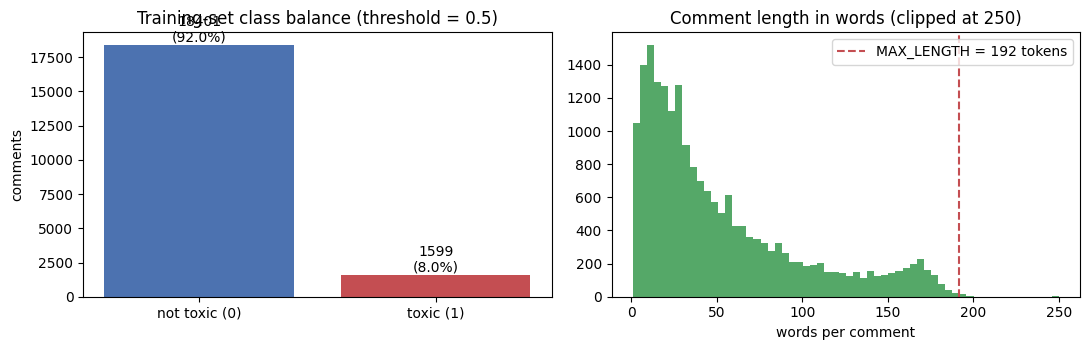

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

93.0% of 2000 sampled comments fit inside 192 tokens


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))

counts = train_df["label"].value_counts().sort_index()
axes[0].bar(["not toxic (0)", "toxic (1)"], counts.values,
            color=["#4c72b0", "#c44e52"])
for i, v in enumerate(counts.values):
    axes[0].text(i, v, f"{v}\n({100*v/len(train_df):.1f}%)", ha="center", va="bottom")
axes[0].set_title(f"Training-set class balance (threshold = {CONFIG['TOXIC_THRESHOLD']})")
axes[0].set_ylabel("comments")

words = train_df["text"].str.split().str.len().clip(upper=250)
axes[1].hist(words, bins=60, color="#55a868")
axes[1].axvline(CONFIG["MAX_LENGTH"], color="#c44e52", ls="--",
                label=f"MAX_LENGTH = {CONFIG['MAX_LENGTH']} tokens")
axes[1].set_title("Comment length in words (clipped at 250)")
axes[1].set_xlabel("words per comment"); axes[1].legend()

plt.tight_layout()
plt.savefig(Path(CONFIG["OUT_FIG"]) / "01_data_overview.png", dpi=150)
plt.show()





tok_check = AutoTokenizer.from_pretrained(CONFIG["MODEL_NAME"])
n_check = min(2000, len(train_df))
sample_texts = train_df["text"].sample(n_check, random_state=CONFIG["SEED"]).tolist()
lengths = [len(tok_check(t)["input_ids"]) for t in sample_texts]
kept = 100 * np.mean(np.array(lengths) <= CONFIG["MAX_LENGTH"])
print(f"{kept:.1f}% of {n_check} sampled comments fit inside {CONFIG['MAX_LENGTH']} tokens")


---
## 3. Shared building blocks

In [13]:
class CommentDataset(Dataset):
    """Holds (text, label) rows; tokenisation happens in the collate function."""
    def __init__(self, frame):
        self.texts = frame["text"].astype(str).tolist()
        self.labels = frame["label"].tolist()
    def __len__(self):
        return len(self.texts)
    def __getitem__(self, i):
        return {"text": self.texts[i], "label": self.labels[i]}


class ToxicityClassifier(nn.Module):
    #Pre-trained transformer backbone + a small classification head.
    def __init__(self, model_name, head_dropout=0.1):
        super().__init__()
        self.backbone = AutoModel.from_pretrained(model_name)
        hidden = self.backbone.config.hidden_size
        self.dropout = nn.Dropout(head_dropout)
        self.head = nn.Linear(hidden, 2)

    def forward(self, input_ids, attention_mask, **kwargs):
        out = self.backbone(input_ids=input_ids, attention_mask=attention_mask)
        cls_vector = out.last_hidden_state[:, 0]        # the [CLS] summary vector
        return self.head(self.dropout(cls_vector))

    def freeze_backbone(self):
        for p in self.backbone.parameters():
            p.requires_grad_(False)

    def trainable_parameter_groups(self, weight_decay):
        """Weight decay on matrices, but not on biases and LayerNorms (standard practice)."""
        decay, no_decay = [], []
        for name, p in self.named_parameters():
            if not p.requires_grad:
                continue
            (no_decay if (name.endswith("bias") or "LayerNorm" in name) else decay).append(p)
        return [{"params": decay, "weight_decay": weight_decay},
                {"params": no_decay, "weight_decay": 0.0}]

tokenizer = AutoTokenizer.from_pretrained(CONFIG["MODEL_NAME"])

def make_collate(tok, max_length):
    def collate(batch):
        texts = [b["text"] for b in batch]
        enc = tok(texts, truncation=True, max_length=max_length,
                  padding=True, return_tensors="pt")
        enc["labels"] = torch.tensor([b["label"] for b in batch])
        return enc
    return collate

collate_fn = make_collate(tokenizer, CONFIG["MAX_LENGTH"])

def make_loader(frame, batch_size, shuffle):
    return DataLoader(CommentDataset(frame), batch_size=batch_size, shuffle=shuffle,
                      collate_fn=collate_fn, num_workers=0)

# A quick shape check on one batch.
_loader = make_loader(train_df.head(4), batch_size=4, shuffle=False)
_batch = next(iter(_loader))
print({k: tuple(v.shape) for k, v in _batch.items()})


{'input_ids': (4, 192), 'token_type_ids': (4, 192), 'attention_mask': (4, 192), 'labels': (4,)}


In [14]:
def compute_metrics(y_true, proba_toxic, threshold=0.5):
    preds = (proba_toxic >= threshold).astype(int)
    return {
        "accuracy":  accuracy_score(y_true, preds),
        "precision": precision_score(y_true, preds, zero_division=0),
        "recall":    recall_score(y_true, preds, zero_division=0),
        "f1":        f1_score(y_true, preds, zero_division=0),
        "roc_auc":   roc_auc_score(y_true, proba_toxic),
        "pr_auc":    average_precision_score(y_true, proba_toxic),
    }


@torch.no_grad()
def predict_proba_texts(model, texts, batch_size=None):
    model.eval()
    bs = batch_size or CONFIG["EVAL_BATCH"]
    model_device = next(model.parameters()).device
    out = []
    for i in range(0, len(texts), bs):
        enc = tokenizer(texts[i:i+bs], truncation=True, max_length=CONFIG["MAX_LENGTH"],
                        padding=True, return_tensors="pt").to(model_device)
        logits = model(**enc)
        prob = torch.softmax(logits, dim=-1)[:, 1]
        out.append(prob.float().cpu().numpy())
    return np.concatenate(out)


@torch.no_grad()
def evaluate_model(model, frame):
    y_true = frame["label"].values
    proba = predict_proba_texts(model, frame["text"].tolist())
    return compute_metrics(y_true, proba), proba


def show_metrics(title, m):
    print(f"{title:34s} acc {m['accuracy']:.4f} | prec {m['precision']:.4f} | "
          f"rec {m['recall']:.4f} | F1 {m['f1']:.4f} | ROC-AUC {m['roc_auc']:.4f} | "
          f"PR-AUC {m['pr_auc']:.4f}")


y_test = test_df["label"].values
majority = compute_metrics(y_test, np.zeros(len(y_test)))
show_metrics("Majority-class baseline (test)", majority)
SUMMARY["baseline_majority_test"] = majority


Majority-class baseline (test)     acc 0.9200 | prec 0.0000 | rec 0.0000 | F1 0.0000 | ROC-AUC 0.5000 | PR-AUC 0.0800


In [15]:
def linear_warmup_then_decay(optimizer, warmup_steps, total_steps):
    def lr_multiplier(step):
        if step < warmup_steps:
            return step / max(1, warmup_steps)
        return max(0.0, (total_steps - step) / max(1, total_steps - warmup_steps))
    return torch.optim.lr_scheduler.LambdaLR(optimizer, lr_multiplier)


def train_classifier(model, train_frame, val_frame, *, learning_rate, batch_size,
                     epochs, warmup_ratio, weight_decay, patience, tag=""):



    set_seed(CONFIG["SEED"])
    model = model.to(device)
    train_loader = make_loader(train_frame, batch_size, shuffle=True)
    val_y = val_frame["label"].values

    optimizer = torch.optim.AdamW(
        model.trainable_parameter_groups(weight_decay), lr=learning_rate)
    total_steps = len(train_loader) * epochs
    warmup_steps = int(total_steps * warmup_ratio)
    scheduler = linear_warmup_then_decay(optimizer, warmup_steps, total_steps)
    loss_fn = nn.CrossEntropyLoss()
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)

    history, best_f1, best_state, bad_epochs = [], -1.0, None, 0
    for epoch in range(1, epochs + 1):
        model.train()
        running = 0.0
        for batch in tqdm(train_loader, leave=False, desc=f"{tag} epoch {epoch}"):
            batch = {k: v.to(device) for k, v in batch.items()}
            optimizer.zero_grad()
            with torch.autocast("cuda", enabled=USE_AMP):
                logits = model(**batch)
                loss = loss_fn(logits, batch["labels"])
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(
                (p for g in optimizer.param_groups for p in g["params"]), 1.0)
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()
            running += loss.item()

        proba = predict_proba_texts(model, val_frame["text"].tolist())
        val_m = compute_metrics(val_y, proba)
        train_loss = running / len(train_loader)
        history.append({"epoch": epoch, "train_loss": train_loss, **val_m})
        star = ""
        if val_m["f1"] > best_f1 + 1e-4:
            best_f1, bad_epochs = val_m["f1"], 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            star = "  <- best so far"
        else:
            bad_epochs += 1
        print(f"{tag} epoch {epoch}: train loss {train_loss:.4f} | "
              f"val F1 {val_m['f1']:.4f} | val acc {val_m['accuracy']:.4f}{star}")
        if bad_epochs >= patience:
            print(f"{tag} early stop (no val-F1 gain for {patience} epochs)")
            break

    if best_state is not None:
        model.load_state_dict(best_state)
    model.eval()
    return history, best_f1





def plot_history(histories, title, fname):
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
    for label, hist in histories:
        ep = [h["epoch"] for h in hist]
        axes[0].plot(ep, [h["train_loss"] for h in hist], marker="o", label=label)
        axes[1].plot(ep, [h["f1"] for h in hist], marker="o", label=label)
    axes[0].set_title(f"{title} - training loss"); axes[0].set_xlabel("epoch")
    axes[1].set_title(f"{title} - validation F1"); axes[1].set_xlabel("epoch")
    for ax in axes: ax.legend(); ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(Path(CONFIG["OUT_FIG"]) / fname, dpi=150)
    plt.show()


---
## 4. Transfer learning: frozen feature extractor (the baseline)


In [16]:
@torch.no_grad()
def extract_cls_features(model, frame, batch_size=None):
    model.eval()
    bs = batch_size or CONFIG["EVAL_BATCH"]
    model = model.to(device)
    feats = []
    texts = frame["text"].astype(str).tolist()
    for i in tqdm(range(0, len(texts), bs), leave=False, desc="extracting features"):
        enc = tokenizer(texts[i:i+bs], truncation=True, max_length=CONFIG["MAX_LENGTH"],
                        padding=True, return_tensors="pt").to(device)
        out = model.backbone(input_ids=enc["input_ids"], attention_mask=enc["attention_mask"])
        feats.append(out.last_hidden_state[:, 0].float().cpu().numpy())
    return np.concatenate(feats)





t0 = time.time()
extractor = ToxicityClassifier(CONFIG["MODEL_NAME"], head_dropout=0.0)
extractor.freeze_backbone()
n_frozen = sum(p.numel() for p in extractor.backbone.parameters())
n_trainable = sum(p.numel() for p in extractor.head.parameters())
print(f"Backbone: {n_frozen/1e6:.1f}M parameters (FROZEN) | "
      f"trainable head: {n_trainable/1e3:.1f}K parameters "
      f"({100*n_trainable/(n_frozen+n_trainable):.3f}% of the model)")

F_train = extract_cls_features(extractor, train_df)
F_val   = extract_cls_features(extractor, val_df)
F_test  = extract_cls_features(extractor, test_df)
print("Cached feature matrices:", F_train.shape, F_val.shape, F_test.shape)
del extractor
SUMMARY["stage_times"]["frozen_extraction_s"] = round(time.time() - t0, 1)


model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Backbone: 66.4M parameters (FROZEN) | trainable head: 1.5K parameters (0.002% of the model)


extracting features:   0%|          | 0/157 [00:00<?, ?it/s]

extracting features:   0%|          | 0/40 [00:00<?, ?it/s]

extracting features:   0%|          | 0/40 [00:00<?, ?it/s]

Cached feature matrices: (20000, 768) (5000, 768) (5000, 768)


/tmp/ipykernel_50/1724352927.py:36: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  hist_head.append({"epoch": epoch, "train_loss": float(loss), "f1": val_f1})


Head converged at val F1 = 0.3089 after 35 epochs (4s)


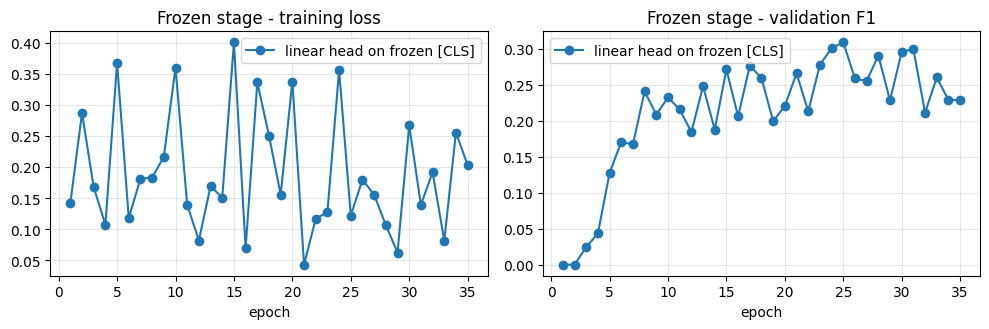

Frozen baseline (val)              acc 0.9266 | prec 0.6260 | rec 0.2050 | F1 0.3089 | ROC-AUC 0.8447 | PR-AUC 0.4046
Frozen baseline (test)             acc 0.9230 | prec 0.5524 | rec 0.1975 | F1 0.2910 | ROC-AUC 0.8524 | PR-AUC 0.3911


In [17]:
set_seed(CONFIG["SEED"])

class LinearHead(nn.Module):
    def __init__(self, in_dim, dropout):
        super().__init__()
        self.dropout = nn.Dropout(dropout)
        self.out = nn.Linear(in_dim, 2)
    def forward(self, x):
        return self.out(self.dropout(x))

head = LinearHead(F_train.shape[1], dropout=0.1).to(device)
opt = torch.optim.AdamW(head.parameters(), lr=CONFIG["HEAD_LR"])
loss_fn = nn.CrossEntropyLoss()

def head_probs(head_nn, feats):
    head_nn.eval()
    with torch.no_grad():
        return torch.softmax(head_nn(torch.from_numpy(feats).to(device)), -1)[:, 1] \
                .cpu().numpy()

Xtr = torch.from_numpy(F_train).to(device)
ytr = torch.from_numpy(train_df["label"].values).to(device)
yv, yt = val_df["label"].values, test_df["label"].values

t0 = time.time()
hist_head, best, bad, best_state = [], -1.0, 0, None
for epoch in range(1, CONFIG["HEAD_EPOCHS"] + 1):
    head.train()
    perm = torch.randperm(len(Xtr), device=device)
    for i in range(0, len(Xtr), 256):
        idx = perm[i:i+256]
        logits = head(Xtr[idx])
        loss = loss_fn(logits, ytr[idx])
        opt.zero_grad(); loss.backward(); opt.step()
    val_f1 = compute_metrics(yv, head_probs(head, F_val))["f1"]
    hist_head.append({"epoch": epoch, "train_loss": float(loss), "f1": val_f1})
    if val_f1 > best + 1e-4:
        best, bad = val_f1, 0
        best_state = copy.deepcopy(head.state_dict())
    else:
        bad += 1
        if bad >= CONFIG["HEAD_PATIENCE"]:
            break
head.load_state_dict(best_state)
print(f"Head converged at val F1 = {best:.4f} after {len(hist_head)} epochs "
      f"({time.time()-t0:.0f}s)")

plot_history([("linear head on frozen [CLS]", hist_head)],
             "Frozen stage", "02_frozen_head.png")



# Test metrics of the frozen baseline
frozen_test = compute_metrics(yt, head_probs(head, F_test))
frozen_val = compute_metrics(yv, head_probs(head, F_val))
show_metrics("Frozen baseline (val)", frozen_val)
show_metrics("Frozen baseline (test)", frozen_test)
SUMMARY["stage1_frozen"] = {"val": frozen_val, "test": frozen_test,
                            "head_params": int(n_trainable),
                            "backbone_params": int(n_frozen)}
torch.save(head.state_dict(), Path(CONFIG["OUT_CKPT"]) / "frozen_head.pt")


---
## 5. Fine-tuning with default hyperparameters


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Trainable parameters: 66.4M (the whole model is unfrozen)


[fine-tune default] epoch 1:   0%|          | 0/625 [00:00<?, ?it/s]

/tmp/ipykernel_50/3135854197.py:43: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


[fine-tune default] epoch 1: train loss 0.2082 | val F1 0.5882 | val acc 0.9440  <- best so far


[fine-tune default] epoch 2:   0%|          | 0/625 [00:00<?, ?it/s]

[fine-tune default] epoch 2: train loss 0.1190 | val F1 0.5932 | val acc 0.9402  <- best so far


[fine-tune default] epoch 3:   0%|          | 0/625 [00:00<?, ?it/s]

[fine-tune default] epoch 3: train loss 0.0713 | val F1 0.5913 | val acc 0.9378


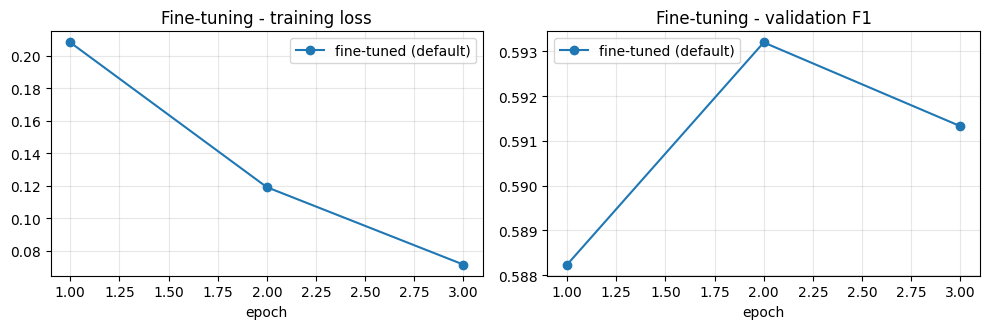

Fine-tuned default (val)           acc 0.9402 | prec 0.6507 | rec 0.5450 | F1 0.5932 | ROC-AUC 0.9380 | PR-AUC 0.6794
Fine-tuned default (test)          acc 0.9428 | prec 0.6676 | rec 0.5675 | F1 0.6135 | ROC-AUC 0.9377 | PR-AUC 0.6907

First comparison (test F1): frozen 0.2910  ->  fine-tuned 0.6135 (+0.3225)


In [18]:
t0 = time.time()
set_seed(CONFIG["SEED"])

model_ft = ToxicityClassifier(CONFIG["MODEL_NAME"],
                              head_dropout=CONFIG["FT_DEFAULT"]["head_dropout"])
print("Trainable parameters:",
      f"{sum(p.numel() for p in model_ft.parameters() if p.requires_grad)/1e6:.1f}M "
      "(the whole model is unfrozen)")

hist_ft, _ = train_classifier(
    model_ft, train_df, val_df,
    learning_rate=CONFIG["FT_DEFAULT"]["learning_rate"],
    batch_size=CONFIG["FT_DEFAULT"]["batch_size"],
    epochs=CONFIG["FT_DEFAULT"]["epochs"],
    warmup_ratio=CONFIG["FT_DEFAULT"]["warmup_ratio"],
    weight_decay=CONFIG["FT_DEFAULT"]["weight_decay"],
    patience=CONFIG["FT_DEFAULT"]["epochs"],   # no early stop: fixed 3-epoch budget
    tag="[fine-tune default]",
)
SUMMARY["stage_times"]["finetune_default_s"] = round(time.time() - t0, 1)

plot_history([("fine-tuned (default)", hist_ft)],
             "Fine-tuning", "03_finetune_default.png")

ft_val,  proba_ft_val = evaluate_model(model_ft, val_df)
ft_test, proba_ft     = evaluate_model(model_ft, test_df)
show_metrics("Fine-tuned default (val)", ft_val)
show_metrics("Fine-tuned default (test)", ft_test)
SUMMARY["stage2_finetuned_default"] = {"config": CONFIG["FT_DEFAULT"],
                                       "val": ft_val, "test": ft_test}
torch.save(model_ft.state_dict(), Path(CONFIG["OUT_CKPT"]) / "finetuned_default.pt")

print()
print("First comparison (test F1): frozen "
      f"{frozen_test['f1']:.4f}  ->  fine-tuned {ft_test['f1']:.4f} "
      f"({ft_test['f1']-frozen_test['f1']:+.4f})")


---
## 6. Hyperparameter tuning of the fine-tuned model


In [19]:
GRID_SPACE = {
    "learning_rate": [1e-5, 2e-5, 5e-5],
    "batch_size":    [16, 32],
}
GRID_FIXED = dict(warmup_ratio=0.06, weight_decay=0.01, head_dropout=0.1)

RANDOM_SPACE = {
    "learning_rate": loguniform(5e-6, 1e-4),
    "batch_size":    [16, 32, 64],
    "warmup_ratio":  [0.0, 0.06, 0.15],
    "weight_decay":  [0.0, 0.01, 0.1],
    "head_dropout":  [0.1, 0.3, 0.5],
}

space_rows = [
    ["learning_rate", "grid + random", "1e-5..1e-5 steps / log 5e-6..1e-4", "usually the most decisive one"],
    ["batch_size",    "grid + random", "{16, 32} / {16, 32, 64}", "gradient noise + memory"],
    ["warmup_ratio",  "random",        "{0.0, 0.06, 0.15}", "stabilises early steps"],
    ["weight_decay",  "random",        "{0.0, 0.01, 0.1}",  "regularisation"],
    ["head_dropout",  "random",        "{0.1, 0.3, 0.5}",   "head regularisation"],
]
display(pd.DataFrame(space_rows, columns=["hyperparameter", "searched by", "values", "why"]))

search_train, _ = train_test_split(
    train_df, train_size=min(CONFIG["SEARCH_SUBSET"], len(train_df)),
    stratify=train_df["label"], random_state=CONFIG["SEED"])
print(f"Each trial trains on {len(search_train)} rows for {CONFIG['SEARCH_EPOCHS']} epochs "
      f"and is scored on the {len(val_df)} validation rows.")

,hyperparameter,searched by,values,why
0,learning_rate,grid + random,1e-5..1e-5 steps / log 5e-6..1e-4,usually the most decisive one
1,batch_size,grid + random,"{16, 32} / {16, 32, 64}",gradient noise + memory
2,warmup_ratio,random,"{0.0, 0.06, 0.15}",stabilises early steps
3,weight_decay,random,"{0.0, 0.01, 0.1}",regularisation
4,head_dropout,random,"{0.1, 0.3, 0.5}",head regularisation


Each trial trains on 8000 rows for 2 epochs and is scored on the 5000 validation rows.


In [20]:
def run_trial(method, trial_id, cfg):
    t0 = time.time()
    model = ToxicityClassifier(CONFIG["MODEL_NAME"], head_dropout=cfg["head_dropout"])
    hist, best_val_f1 = train_classifier(
        model, search_train, val_df,
        learning_rate=cfg["learning_rate"], batch_size=cfg["batch_size"],
        epochs=CONFIG["SEARCH_EPOCHS"], warmup_ratio=cfg["warmup_ratio"],
        weight_decay=cfg["weight_decay"],
        patience=CONFIG["SEARCH_EPOCHS"] + 1,      # fixed budget, no early stop
        tag=f"[{method} #{trial_id}]")
    val_m = compute_metrics(val_df["label"].values,
                            predict_proba_texts(model, val_df["text"].tolist()))
    minutes = (time.time() - t0) / 60


    del model
    if device.type == "cuda":
        torch.cuda.empty_cache()
    rec = {"method": method, "trial": trial_id, **cfg,
           "train_loss": round(hist[-1]["train_loss"], 4),
           "val_f1": round(val_m["f1"], 4), "val_acc": round(val_m["accuracy"], 4),
           "val_roc_auc": round(val_m["roc_auc"], 4),
           "val_pr_auc": round(val_m["pr_auc"], 4),
           "minutes": round(minutes, 2)}
    print(f"--> {method} #{trial_id} done: val F1 {rec['val_f1']:.4f} "
          f"({rec['minutes']:.1f} min)  {cfg}")
    return rec

trials = []

# Grid Search
print("=" * 100); print("GRID SEARCH"); print("=" * 100)
gid = 0
for lr in GRID_SPACE["learning_rate"]:
    for bs in GRID_SPACE["batch_size"]:
        gid += 1
        cfg = dict(learning_rate=lr, batch_size=bs, **GRID_FIXED)
        trials.append(run_trial("grid", gid, cfg))


GRID SEARCH


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


[grid #1] epoch 1:   0%|          | 0/500 [00:00<?, ?it/s]

/tmp/ipykernel_50/3135854197.py:43: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


[grid #1] epoch 1: train loss 0.2470 | val F1 0.4968 | val acc 0.9364  <- best so far


... (33 outputs left out)

/tmp/ipykernel_50/3135854197.py:43: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


[grid #6] epoch 1: train loss 0.2209 | val F1 0.5068 | val acc 0.9416  <- best so far


[grid #6] epoch 2:   0%|          | 0/250 [00:00<?, ?it/s]

[grid #6] epoch 2: train loss 0.0973 | val F1 0.5916 | val acc 0.9398  <- best so far
--> grid #6 done: val F1 0.5916 (2.6 min)  {'learning_rate': 5e-05, 'batch_size': 32, 'warmup_ratio': 0.06, 'weight_decay': 0.01, 'head_dropout': 0.1}


In [21]:
# Random Search
print("=" * 100); print("RANDOM SEARCH"); print("=" * 100)
rng = np.random.RandomState(CONFIG["SEED"])
for rid in range(1, CONFIG["RANDOM_TRIALS"] + 1):
    cfg = {k: (v.rvs(random_state=rng) if hasattr(v, "rvs") else rng.choice(v))
           for k, v in RANDOM_SPACE.items()}
    cfg["batch_size"] = int(cfg["batch_size"])
    trials.append(run_trial("random", rid, cfg))

trials_df = pd.DataFrame(trials).sort_values("val_f1", ascending=False).reset_index(drop=True)
trials_df.to_csv(Path(CONFIG["OUT_RES"]) / "search_trials.csv", index=False)

print()
print("=" * 100)
print("ALL TRIALS, RANKED BY VALIDATION F1  <-- screenshot this table for the README")
print("=" * 100)
print(trials_df.to_string())


RANDOM SEARCH


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


[random #1] epoch 1:   0%|          | 0/500 [00:00<?, ?it/s]

/tmp/ipykernel_50/3135854197.py:43: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


[random #1] epoch 1: train loss 0.2496 | val F1 0.5743 | val acc 0.9410  <- best so far


... (75 outputs left out)

/tmp/ipykernel_50/3135854197.py:43: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


[random #12] epoch 1: train loss 0.2548 | val F1 0.4704 | val acc 0.9356  <- best so far


[random #12] epoch 2:   0%|          | 0/500 [00:00<?, ?it/s]

[random #12] epoch 2: train loss 0.1600 | val F1 0.5255 | val acc 0.9368  <- best so far
--> random #12 done: val F1 0.5255 (2.8 min)  {'learning_rate': np.float64(8.404707789959712e-06), 'batch_size': 16, 'warmup_ratio': np.float64(0.06), 'weight_decay': np.float64(0.01), 'head_dropout': np.float64(0.3)}

ALL TRIALS, RANKED BY VALIDATION F1  <-- screenshot this table for the README
    method  trial  learning_rate  batch_size  warmup_ratio  weight_decay  head_dropout  train_loss  val_f1  val_acc  val_roc_auc  val_pr_auc  minutes
0   random     10       0.000090          32          0.06          0.00           0.3      0.0925  0.5958   0.9384       0.9283      0.6352     2.57
1   random      4       0.000091          32          0.06          0.01           0.1      0.0936  0.5924   0.9378       0.9312      0.6417     2.59
2   random      1       0.000015          16          0.15          0.10           0.1      0.1336  0.5923   0.9430       0.9262      0.6370     2.82
3   random    

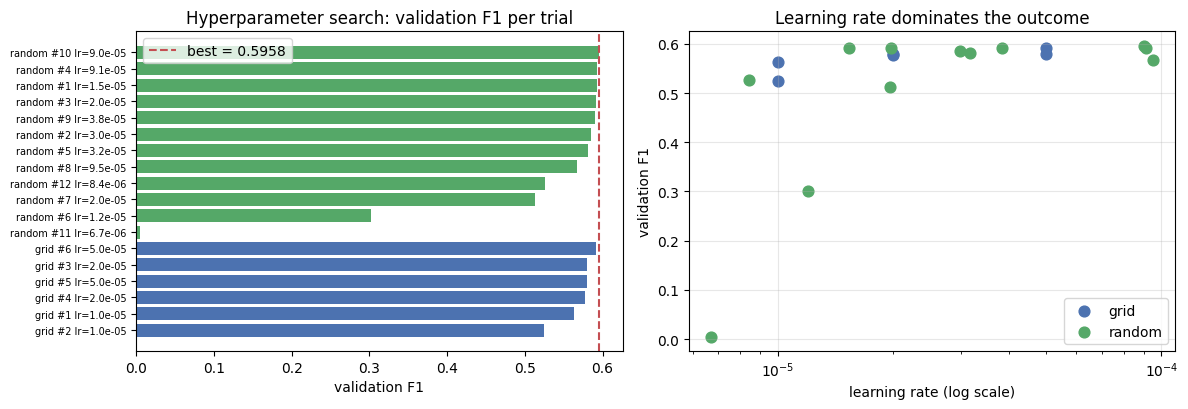

BEST CONFIGURATION (random #10, val F1 = 0.5958):
{
  "learning_rate": 9.021655603568134e-05,
  "batch_size": 32,
  "warmup_ratio": 0.06,
  "weight_decay": 0.0,
  "head_dropout": 0.3
}
Grid best    : 0.5916
Random best  : 0.5958


In [22]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

ordered = trials_df.sort_values(["method", "val_f1"]).reset_index(drop=True)
colors = {"grid": "#4c72b0", "random": "#55a868"}
axes[0].barh(range(len(ordered)), ordered["val_f1"],
             color=[colors[m] for m in ordered["method"]])
axes[0].set_yticks(range(len(ordered)))
axes[0].set_yticklabels([f"{r.method} #{r.trial} lr={r.learning_rate:.1e}"
                         for _, r in ordered.iterrows()], fontsize=7)
axes[0].axvline(trials_df["val_f1"].max(), color="#c44e52", ls="--",
                label=f"best = {trials_df['val_f1'].max():.4f}")
axes[0].set_title("Hyperparameter search: validation F1 per trial")
axes[0].set_xlabel("validation F1"); axes[0].legend()

for m, grp in trials_df.groupby("method"):
    axes[1].scatter(grp["learning_rate"], grp["val_f1"], s=60, label=m, color=colors[m])
axes[1].set_xscale("log"); axes[1].set_xlabel("learning rate (log scale)")
axes[1].set_ylabel("validation F1"); axes[1].grid(alpha=0.3)
axes[1].set_title("Learning rate dominates the outcome")
axes[1].legend()

plt.tight_layout()
plt.savefig(Path(CONFIG["OUT_FIG"]) / "04_tuning_results.png", dpi=150)
plt.show()

best_row = trials_df.iloc[0]
BEST_CONFIG = {k: (int(best_row[k]) if k == "batch_size" else float(best_row[k]))
               for k in ["learning_rate", "batch_size", "warmup_ratio",
                         "weight_decay", "head_dropout"]}
print(f"BEST CONFIGURATION ({best_row['method']} #{best_row['trial']}, "
      f"val F1 = {best_row['val_f1']:.4f}):")
print(json.dumps(BEST_CONFIG, indent=2))
print(f"Grid best    : {trials_df[trials_df.method=='grid']['val_f1'].max():.4f}")
print(f"Random best  : {trials_df[trials_df.method=='random']['val_f1'].max():.4f}")
SUMMARY["stage3_search"] = {
    "n_grid_trials": int((trials_df.method == "grid").sum()),
    "n_random_trials": int((trials_df.method == "random").sum()),
    "grid_best_val_f1": round(float(trials_df[trials_df.method == "grid"]["val_f1"].max()), 4),
    "random_best_val_f1": round(float(trials_df[trials_df.method == "random"]["val_f1"].max()), 4),
    "best_config": BEST_CONFIG,
    "best_val_f1": round(float(best_row["val_f1"]), 4),
    "search_subset_rows": len(search_train),
    "search_epochs": CONFIG["SEARCH_EPOCHS"],
}


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


[final tuned] epoch 1:   0%|          | 0/625 [00:00<?, ?it/s]

/tmp/ipykernel_50/3135854197.py:43: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


[final tuned] epoch 1: train loss 0.2073 | val F1 0.5593 | val acc 0.9376  <- best so far


[final tuned] epoch 2:   0%|          | 0/625 [00:00<?, ?it/s]

... (3 outputs left out)

[final tuned] epoch 4:   0%|          | 0/625 [00:00<?, ?it/s]

[final tuned] epoch 4: train loss 0.0091 | val F1 0.5804 | val acc 0.9358  <- best so far


[final tuned] epoch 5:   0%|          | 0/625 [00:00<?, ?it/s]

[final tuned] epoch 5: train loss 0.0017 | val F1 0.5666 | val acc 0.9382


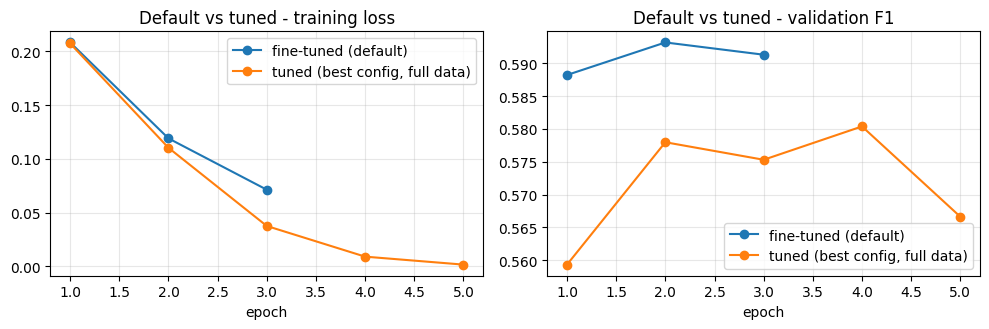

Tuned final (val)                  acc 0.9358 | prec 0.6082 | rec 0.5550 | F1 0.5804 | ROC-AUC 0.8887 | PR-AUC 0.6001
Tuned final (test)                 acc 0.9358 | prec 0.6010 | rec 0.5875 | F1 0.5942 | ROC-AUC 0.8898 | PR-AUC 0.6003


In [23]:
# Retrain the winning configuration on the FULL training set
t0 = time.time()
set_seed(CONFIG["SEED"])
model_tuned = ToxicityClassifier(CONFIG["MODEL_NAME"],
                                 head_dropout=BEST_CONFIG["head_dropout"])
hist_tuned, _ = train_classifier(
    model_tuned, train_df, val_df,
    learning_rate=BEST_CONFIG["learning_rate"], batch_size=BEST_CONFIG["batch_size"],
    epochs=CONFIG["FINAL_EPOCHS"], warmup_ratio=BEST_CONFIG["warmup_ratio"],
    weight_decay=BEST_CONFIG["weight_decay"], patience=CONFIG["FINAL_PATIENCE"],
    tag="[final tuned]")
SUMMARY["stage_times"]["final_retrain_s"] = round(time.time() - t0, 1)

plot_history([("fine-tuned (default)", hist_ft), ("tuned (best config, full data)", hist_tuned)],
             "Default vs tuned", "05_final_training.png")

tuned_val,  _          = evaluate_model(model_tuned, val_df)
tuned_test, proba_tuned = evaluate_model(model_tuned, test_df)
show_metrics("Tuned final (val)", tuned_val)
show_metrics("Tuned final (test)", tuned_test)
SUMMARY["stage3_tuned_final"] = {"config": BEST_CONFIG, "val": tuned_val, "test": tuned_test}
torch.save(model_tuned.state_dict(), Path(CONFIG["OUT_CKPT"]) / "tuned_final.pt")


---
## 7. Comparison: frozen baseline vs fine-tuned vs tuned



TEST METRICS (decision threshold = 0.5)
                          accuracy  precision  recall      f1  roc_auc  pr_auc
Majority class (floor)      0.9200     0.0000  0.0000  0.0000   0.5000  0.0800
1. Frozen + linear head     0.9230     0.5524  0.1975  0.2910   0.8524  0.3911
2. Fine-tuned (defaults)    0.9428     0.6676  0.5675  0.6135   0.9377  0.6907
3. Fine-tuned (tuned)       0.9358     0.6010  0.5875  0.5942   0.8898  0.6003


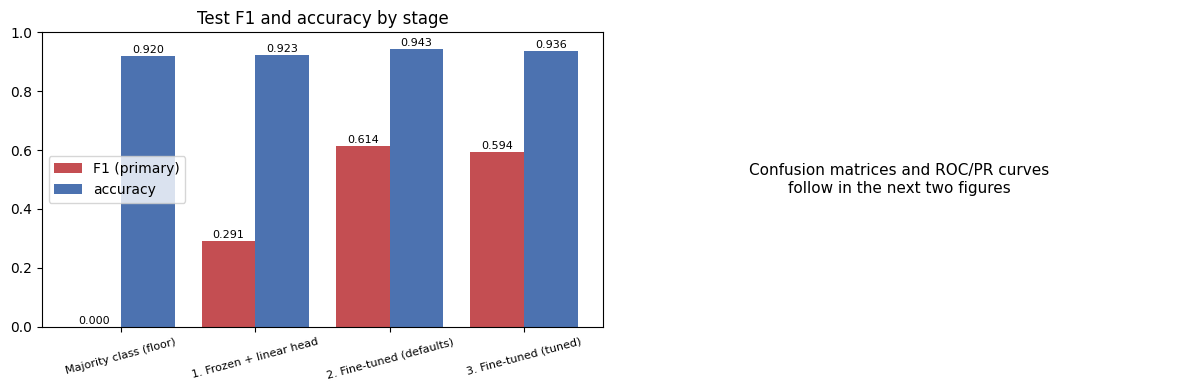

In [24]:
rows = [
    ("Majority class (floor)", SUMMARY["baseline_majority_test"]),
    ("1. Frozen + linear head", SUMMARY["stage1_frozen"]["test"]),
    ("2. Fine-tuned (defaults)", SUMMARY["stage2_finetuned_default"]["test"]),
    ("3. Fine-tuned (tuned)", SUMMARY["stage3_tuned_final"]["test"]),
]
comp_df = pd.DataFrame({name: m for name, m in rows}).T
metric_cols = ["accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc"]
comp_df = comp_df[metric_cols].astype(float).round(4)
print("TEST METRICS (decision threshold = 0.5)")
print(comp_df.to_string())
comp_df.to_csv(Path(CONFIG["OUT_RES"]) / "test_metrics_all_stages.csv")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
x = np.arange(len(comp_df))
axes[0].bar(x - 0.2, comp_df["f1"], 0.4, label="F1 (primary)", color="#c44e52")
axes[0].bar(x + 0.2, comp_df["accuracy"], 0.4, label="accuracy", color="#4c72b0")
axes[0].set_xticks(x); axes[0].set_xticklabels(comp_df.index, rotation=15, fontsize=8)
axes[0].set_ylim(0, 1); axes[0].legend(); axes[0].set_title("Test F1 and accuracy by stage")
for i, (f1v, accv) in enumerate(zip(comp_df["f1"], comp_df["accuracy"])):
    axes[0].text(i - 0.2, f1v + 0.01, f"{f1v:.3f}", ha="center", fontsize=8)
    axes[0].text(i + 0.2, accv + 0.01, f"{accv:.3f}", ha="center", fontsize=8)
axes[0].set_title("Test F1 and accuracy by stage")

axes[1].axis("off")
axes[1].text(0.5, 0.5, "Confusion matrices and ROC/PR curves\nfollow in the next two figures",
             ha="center", va="center", fontsize=11)
plt.tight_layout()
plt.savefig(Path(CONFIG["OUT_FIG"]) / "06_stage_comparison.png", dpi=150)
plt.show()


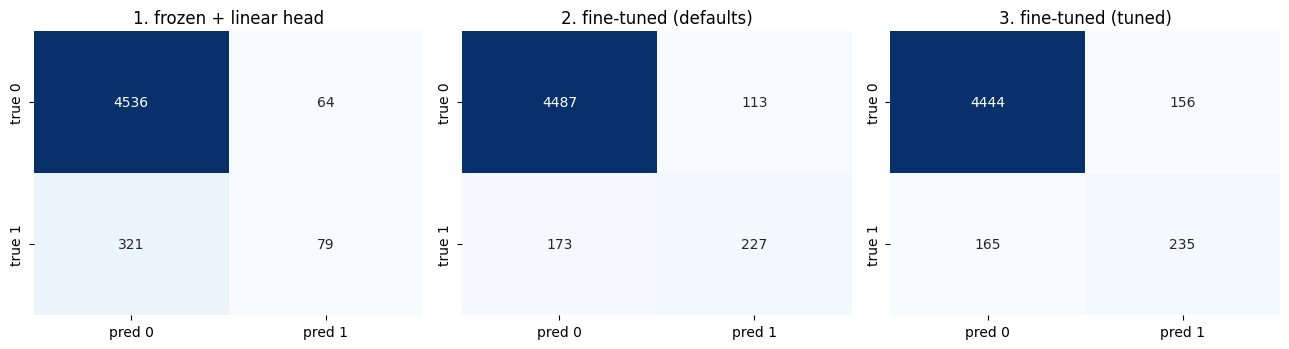

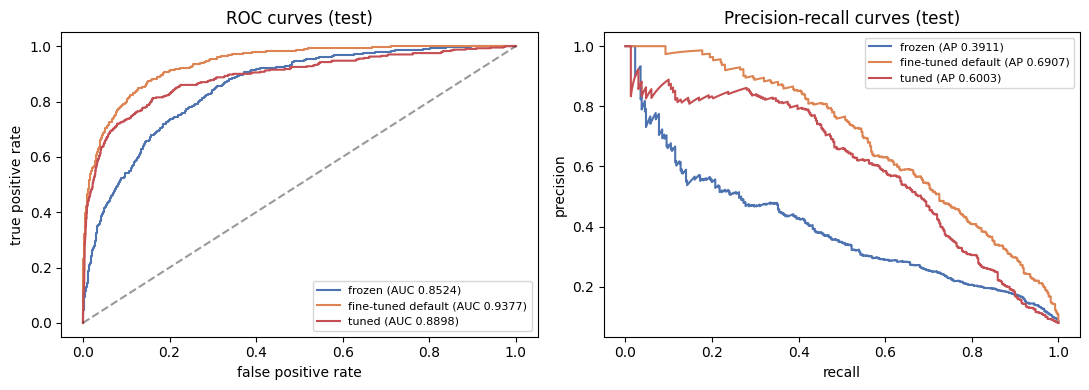

In [34]:
proba_frozen_test = head_probs(head, F_test)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, p, t in zip(axes, [proba_frozen_test, proba_ft, proba_tuned],
                    ["1. frozen + linear head", "2. fine-tuned (defaults)",
                     "3. fine-tuned (tuned)"]):
    cm = confusion_matrix(y_test, (p >= 0.5).astype(int))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["pred 0", "pred 1"], yticklabels=["true 0", "true 1"])
    ax.set_title(t)
plt.tight_layout()
plt.savefig(Path(CONFIG["OUT_FIG"]) / "07_confusion_matrices.png", dpi=150)
plt.show()



fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for p, t, c in zip([proba_frozen_test, proba_ft, proba_tuned],
                   ["frozen", "fine-tuned default", "tuned"],
                   ["#4c72b0", "#dd8452", "#c44e52"]):
    fpr, tpr, _ = roc_curve(y_test, p)
    axes[0].plot(fpr, tpr, color=c,
                 label=f"{t} (AUC {roc_auc_score(y_test, p):.4f})")
    pr, rc, _ = precision_recall_curve(y_test, p)
    axes[1].plot(rc, pr, color=c,
                 label=f"{t} (AP {average_precision_score(y_test, p):.4f})")
axes[0].plot([0, 1], [0, 1], "k--", alpha=0.4)
axes[0].set_xlabel("false positive rate"); axes[0].set_ylabel("true positive rate")
axes[0].set_title("ROC curves (test)"); axes[0].legend(fontsize=8)
axes[1].set_xlabel("recall"); axes[1].set_ylabel("precision")
axes[1].set_title("Precision-recall curves (test)"); axes[1].legend(fontsize=8)
plt.tight_layout()
plt.savefig(Path(CONFIG["OUT_FIG"]) / "08_roc_pr_curves.png", dpi=150)
plt.show()


Best validation-F1 threshold: 0.63 (val F1 0.5878 at that threshold)
Tuned @ threshold 0.63 (test)      acc 0.9358 | prec 0.6048 | rec 0.5700 | F1 0.5869 | ROC-AUC 0.8898 | PR-AUC 0.6003


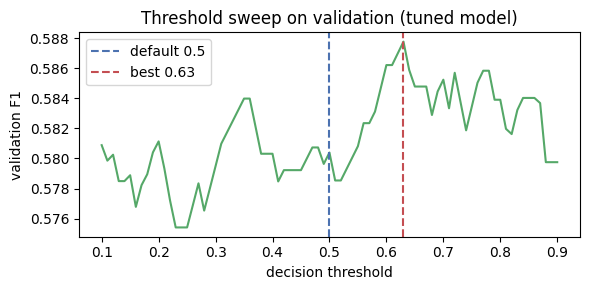

In [35]:
thresholds = np.linspace(0.10, 0.90, 81)
proba_val_tuned = predict_proba_texts(model_tuned, val_df["text"].tolist())
y_val = val_df["label"].values
f1s = [f1_score(y_val, (proba_val_tuned >= t).astype(int)) for t in thresholds]
best_t = float(thresholds[int(np.argmax(f1s))])
tuned_test_best_t = compute_metrics(y_test, proba_tuned, threshold=best_t)
print(f"Best validation-F1 threshold: {best_t:.2f} "
      f"(val F1 {max(f1s):.4f} at that threshold)")
show_metrics(f"Tuned @ threshold {best_t:.2f} (test)", tuned_test_best_t)



plt.figure(figsize=(6, 3))
plt.plot(thresholds, f1s, color="#55a868")
plt.axvline(0.5, color="#4c72b0", ls="--", label="default 0.5")
plt.axvline(best_t, color="#c44e52", ls="--", label=f"best {best_t:.2f}")
plt.xlabel("decision threshold"); plt.ylabel("validation F1")
plt.title("Threshold sweep on validation (tuned model)")
plt.legend(); plt.tight_layout()
plt.savefig(Path(CONFIG["OUT_FIG"]) / "09_threshold_sweep.png", dpi=150)
plt.show()

SUMMARY["threshold_analysis"] = {"best_threshold": round(best_t, 2),
                                 "test_metrics_at_best_threshold": tuned_test_best_t}


---
## 8. Interpretability


In [36]:
proba_test_tuned = proba_tuned
sel = {}
toxic_idx = np.where(y_test == 1)[0]
clean_idx = np.where(y_test == 0)[0]
sel["toxic_confident"] = toxic_idx[np.argmax(proba_test_tuned[toxic_idx])]
sel["clean_confident"] = clean_idx[np.argmin(proba_test_tuned[clean_idx])]
sel["borderline"] = int(np.argmin(np.abs(proba_test_tuned - 0.5)))
fn = toxic_idx[proba_test_tuned[toxic_idx] < 0.3]
sel["error_false_negative"] = int(fn[np.argmin(proba_test_tuned[fn])]) if len(fn) else int(toxic_idx[-1])

EXAMPLES = {}
for name, idx in sel.items():
    text = test_df["text"].iloc[idx]
    EXAMPLES[name] = text
    print(f"[{name}] true={y_test[idx]}  P(toxic)={proba_test_tuned[idx]:.4f}")
    print("   ", repr(text[:200]), "\n")


[toxic_confident] true=1  P(toxic)=0.9999
    'Pocahontas?  Can you ever stop being a loathsome racist imbecile?  Maybe just one day?\n\nYou certainly are a Trump voter!' 

[clean_confident] true=0  P(toxic)=0.0000
    "This implies the US is more correct than Canada.  I don't know much about the details.  Can you post why it is that Canada regularly wins in the courts, after x years?  I am not knowledgeable enough t" 

[borderline] true=0  P(toxic)=0.4895
    "Trump's confused bluster and blather make him look weak.  Beware listening to Generals who have yet to win a war.  They are all losers who keep racking up more budgetary gains while losing in Iraq, Li" 

[error_false_negative] true=1  P(toxic)=0.0000
    'I can\'t even say that the majority of Hillary supporters are peaceful here, without getting called "deplorable" by this guy.  Tough crowd.' 



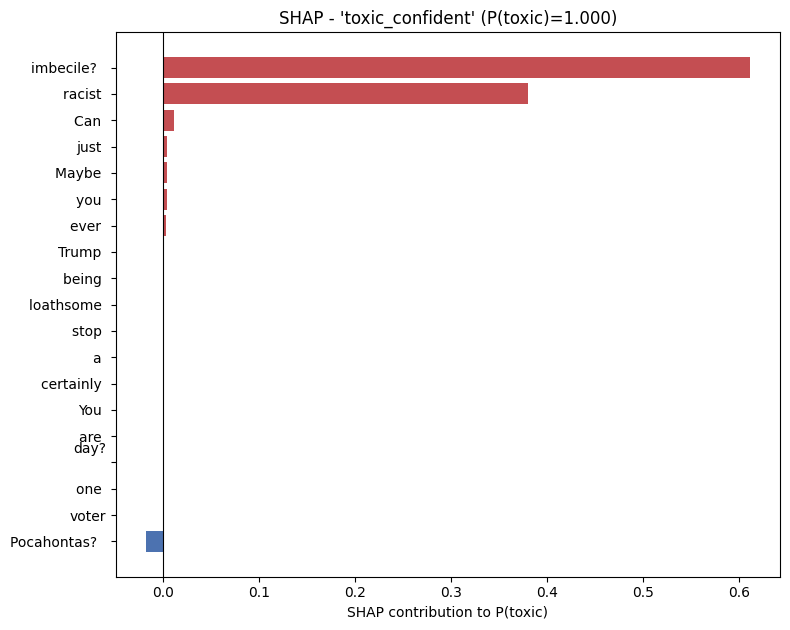

[toxic_confident] top SHAP tokens: imbecile?  :+0.612, racist :+0.380, Pocahontas?  :-0.018, Can :+0.011, just :+0.004, Maybe :+0.004, you :+0.004, ever :+0.003, Trump :+0.001, voter:-0.000



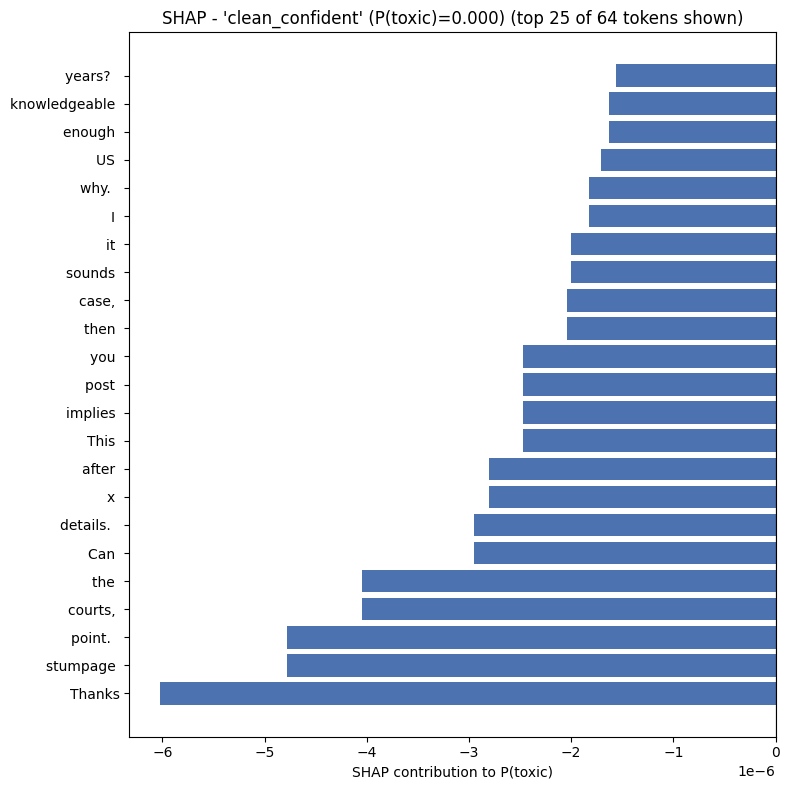

[clean_confident] top SHAP tokens: Thanks:-0.000, stumpage :-0.000, point.  :-0.000, courts, :-0.000, the :-0.000, Can :-0.000, details.  :-0.000, x :-0.000, after :-0.000, This :-0.000



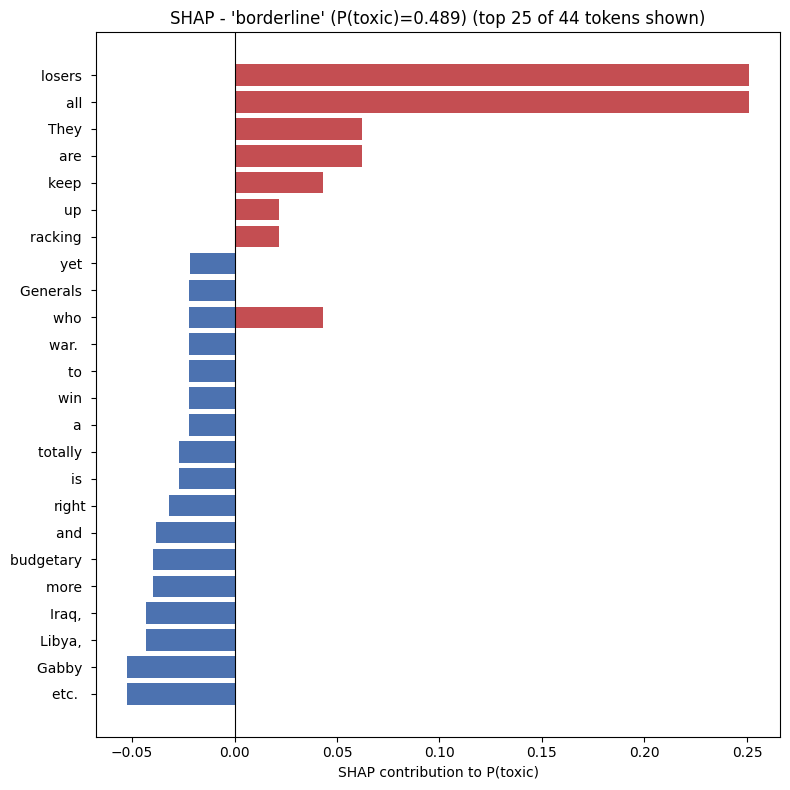

[borderline] top SHAP tokens: losers :+0.251, all :+0.251, They :+0.062, are :+0.062, Gabby :-0.052, etc.  :-0.052, keep :+0.043, who :+0.043, Iraq, :-0.043, Libya, :-0.043



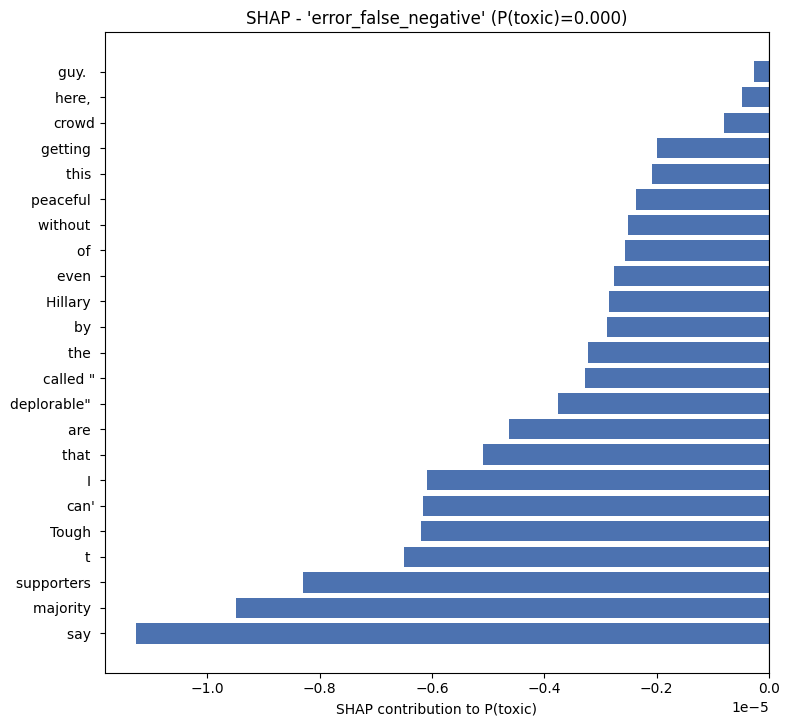

[error_false_negative] top SHAP tokens: say :-0.000, majority :-0.000, supporters :-0.000, t :-0.000, Tough :-0.000, can':-0.000, I :-0.000, that :-0.000, are :-0.000, deplorable" :-0.000



In [37]:
# SHAP
import re
import shap

def predict_toxic(texts):
    """list[str] -> P(toxic). The only function SHAP is allowed to call."""
    if isinstance(texts, str):
        texts = [texts]
    return predict_proba_texts(model_tuned, list(texts))

def plot_token_contributions(tokens, values, title, fname, top_k=25):
    """Diverging bar chart of one example's SHAP token contributions.
    Red pushes toward 'toxic', blue toward 'not toxic'. Only the top_k most
    influential tokens are drawn so long comments stay readable."""
    order_all = np.argsort(-np.abs(values))
    keep = order_all[:top_k]
    n_hidden = max(0, len(values) - len(keep))
    order = keep[np.argsort(values[keep])]
    toks = [str(tokens[j]) for j in order]
    vals = np.asarray(values)[order]
    colors = ["#c44e52" if v > 0 else "#4c72b0" for v in vals]
    if n_hidden:
        title += f" (top {len(keep)} of {len(values)} tokens shown)"
    plt.figure(figsize=(8, max(2.0, 0.32 * len(toks))))
    plt.barh(toks, vals, color=colors)
    plt.axvline(0, color="k", lw=0.8)
    plt.title(title); plt.xlabel("SHAP contribution to P(toxic)")
    plt.tight_layout()
    plt.savefig(Path(CONFIG["OUT_FIG"]) / fname, dpi=150)
    plt.show()

shap_explainer = shap.Explainer(predict_toxic, shap.maskers.Text(r"\W+"))

def explain_text_shap(text):
    """Explain one comment. max_evals must be at least 2 * n_tokens + 1 for the
    partition algorithm, so it is sized to the text (long comments get more budget)."""
    n_tok = len([t for t in re.split(r"\W+", text) if t])
    max_evals = max(CONFIG["SHAP_MAX_EVALS"], 2 * n_tok + 2)
    sv = shap_explainer([text], max_evals=max_evals, batch_size=64)
    toks = [str(t) for t in sv.data[0]]
    vals = np.asarray(sv.values[0]).ravel()
    return toks, vals



EXAMPLES_SHAP = {}
for name, text in EXAMPLES.items():
    toks, vals = explain_text_shap(text)
    EXAMPLES_SHAP[name] = (toks, vals)
    plot_token_contributions(
        toks, vals,
        f"SHAP - '{name}' (P(toxic)={proba_test_tuned[sel[name]]:.3f})",
        f"10_shap_{name}.png")
    order = np.argsort(-np.abs(vals))[:10]
    parts = ", ".join(f"{toks[j]}:{vals[j]:+.3f}" for j in order if toks[j].strip())
    print(f"[{name}] top SHAP tokens: {parts}\n")


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


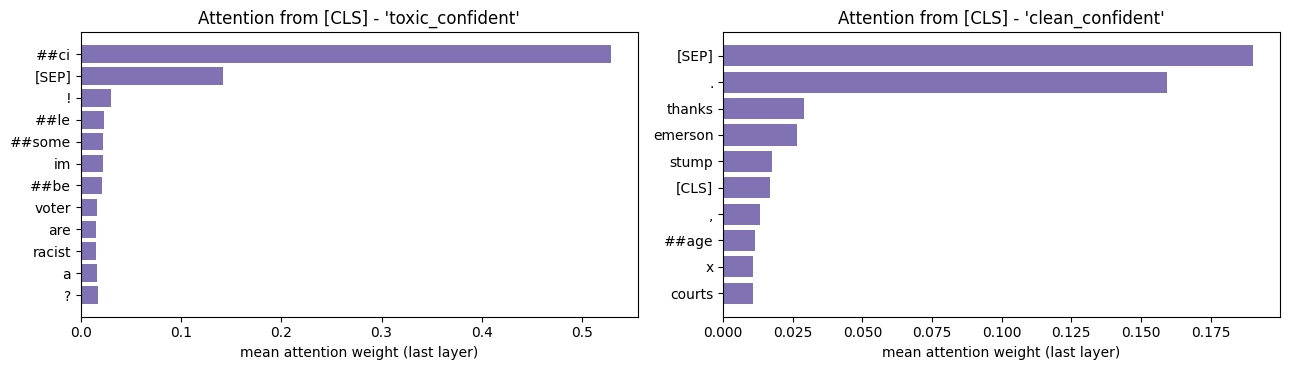

[toxic_confident] top-attended tokens: ##ci (0.529), [SEP] (0.142), ! (0.030), ##le (0.023), ##some (0.022), im (0.022), ##be (0.021), ? (0.017)
[clean_confident] top-attended tokens: [SEP] (0.190), . (0.159), . (0.099), . (0.065), . (0.055), . (0.046), thanks (0.029), emerson (0.026)


In [38]:
attn_backbone = AutoModel.from_pretrained(CONFIG["MODEL_NAME"],
                                          attn_implementation="eager")
attn_backbone.load_state_dict(model_tuned.backbone.state_dict())
attn_backbone = attn_backbone.to(device).eval()

def attention_weights(text):
    """Last-layer attention paid BY [CLS] TO each token, averaged over heads."""
    enc = tokenizer(text, truncation=True, max_length=CONFIG["MAX_LENGTH"],
                    return_tensors="pt").to(device)
    with torch.no_grad():
        out = attn_backbone(input_ids=enc["input_ids"],
                            attention_mask=enc["attention_mask"],
                            output_attentions=True)
    last = out.attentions[-1][0].mean(dim=0)
    cls_row = last[0].cpu().numpy()
    tokens = tokenizer.convert_ids_to_tokens(enc["input_ids"][0])
    return tokens, cls_row

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, name in zip(axes, ["toxic_confident", "clean_confident"]):
    toks, w = attention_weights(EXAMPLES[name])
    top = np.argsort(-w)[:14]
    ax.barh(np.array(toks)[top][::-1], w[top][::-1], color="#8172b3")
    ax.set_title(f"Attention from [CLS] - '{name}'")
    ax.set_xlabel("mean attention weight (last layer)")
plt.tight_layout()
plt.savefig(Path(CONFIG["OUT_FIG"]) / "11_attention_weights.png", dpi=150)
plt.show()

for name in ["toxic_confident", "clean_confident"]:
    toks, w = attention_weights(EXAMPLES[name])
    top = np.argsort(-w)[:8]
    print(f"[{name}] top-attended tokens:",
          ", ".join(f"{toks[j]} ({w[j]:.3f})" for j in top))


LIME weights for 'toxic_confident':
   imbecile             +0.6696
   racist               +0.1980
   loathsome            +0.1067
   Can                  -0.0813
   Pocahontas           -0.0769
   You                  +0.0630
   day                  -0.0592
   certainly            -0.0536
   are                  +0.0342
   ever                 +0.0321


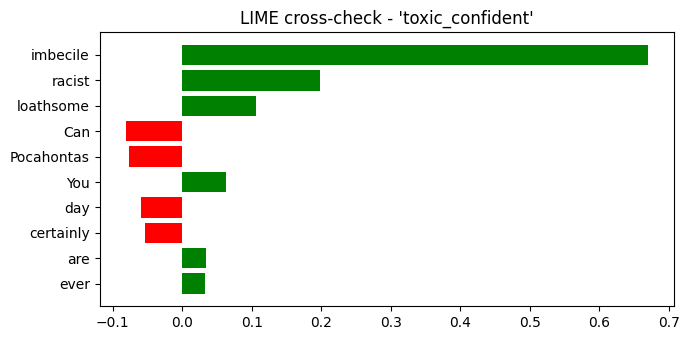

In [39]:
# LIME
from lime.lime_text import LimeTextExplainer

lime_explainer = LimeTextExplainer(class_names=["not toxic", "toxic"], random_state=42)

def predict_two_classes(texts):
    """LIME wants (n, 2) class probabilities."""
    p1 = predict_toxic(list(texts))
    return np.column_stack([1 - p1, p1])

lime_exp = lime_explainer.explain_instance(
    EXAMPLES["toxic_confident"], predict_two_classes,
    num_features=10, num_samples=CONFIG["LIME_SAMPLES"])
print("LIME weights for 'toxic_confident':")
for tok, weight in lime_exp.as_list()[:10]:
    print(f"   {tok:20s} {weight:+.4f}")

figl = lime_exp.as_pyplot_figure()
figl.set_size_inches(7, 3.5)
figl.get_axes()[0].set_title("LIME cross-check - 'toxic_confident'")
figl.tight_layout()
figl.savefig(Path(CONFIG["OUT_FIG"]) / "12_lime_crosscheck.png", dpi=150)
plt.show()


In [40]:
def top_tokens_from_weights(pairs, k=10):
    d = {}
    for tok, w in pairs:
        d[tok.lower()] = d.get(tok.lower(), 0.0) + abs(w)
    return dict(sorted(d.items(), key=lambda kv: -kv[1])[:k])

sv_toks, sv_vals = EXAMPLES_SHAP["toxic_confident"]
shap_tok = top_tokens_from_weights(zip(sv_toks, sv_vals))
lime_tok = top_tokens_from_weights([(t.lower(), w) for t, w in lime_exp.as_list()])
atks, aw = attention_weights(EXAMPLES["toxic_confident"])
att_tok = top_tokens_from_weights(zip(atks, aw))

def agreement(a, b, label):
    shared = sorted(set(a) & set(b))
    jac = len(set(a) & set(b)) / len(set(a) | set(b))
    if len(shared) >= 3:
        rho = spearmanr([a[t] for t in shared], [b[t] for t in shared]).statistic
    else:
        rho = float("nan")
    print(f"{label:18s} Jaccard {jac:.2f} | Spearman(ranked weights) {rho:+.2f} "
          f"| shared tokens {shared}")
    return {"jaccard": round(jac, 2), "spearman": round(float(rho), 2) if rho == rho else None}

print("Method agreement on the 'toxic_confident' example (top-10 token sets):")
agree_sl = agreement(shap_tok, lime_tok, "SHAP vs LIME")
agree_sa = agreement(shap_tok, att_tok, "SHAP vs attention")
agree_la = agreement(lime_tok, att_tok, "LIME vs attention")

SUMMARY["interpretability"] = {
    "explained_examples": {k: {"true": int(y_test[v]),
                               "p_toxic": round(float(proba_test_tuned[v]), 4)}
                           for k, v in sel.items()},
    "methods": ["SHAP partition (primary)", "LIME (cross-check)",
                "attention weights (model-internal)"],
    "agreement": {"shap_vs_lime": agree_sl, "shap_vs_attention": agree_sa,
                  "lime_vs_attention": agree_la},
    "top_shap_tokens": {name: " ".join(
        [toks[j] for j in np.argsort(-np.abs(vals))[:8]])
        for name, (toks, vals) in EXAMPLES_SHAP.items()},
}


Method agreement on the 'toxic_confident' example (top-10 token sets):
SHAP vs LIME       Jaccard 0.00 | Spearman(ranked weights) +nan | shared tokens []
SHAP vs attention  Jaccard 0.05 | Spearman(ranked weights) +nan | shared tokens ['voter']
LIME vs attention  Jaccard 0.00 | Spearman(ranked weights) +nan | shared tokens []


---
## 8. Test on real-world text


In [41]:
DEMO_COMMENTS = [
    "This article really helped me understand the topic, thank you for writing it!",
    "I disagree with the author, but the argument is well made and clearly explained.",
    "This is the stupidest thing I have read all week.",
    "You clearly have no idea what you are talking about.",
    "What a complete waste of time this video was.",
    "Great work as always, looking forward to the next part!",
    "The author should be ashamed of publishing this nonsense.",
    "Can someone explain step three? I did not quite follow it.",
    "Honestly, this changed my mind about the whole topic. Well done.",
    "Stop spreading lies, you are misleading everyone who reads this.",
]

demo_proba = predict_toxic(DEMO_COMMENTS)
demo_df = pd.DataFrame({
    "input": DEMO_COMMENTS,
    "P(toxic)": [round(float(p), 4) for p in demo_proba],
    "predicted": ["TOXIC" if p >= 0.5 else "NOT TOXIC" for p in demo_proba],
})
demo_df["human check"] = [
    "polite and positive -> not toxic. Correct.",
    "civil disagreement -> not toxic. Correct.",
    "calls the content 'stupid' -> insult, toxic. Correct." ,
    "dismissive put-down of the person -> toxic. Correct.",
    "harsh negative opinion of the video -> mildly toxic. Correct.",
    "friendly praise -> not toxic. Correct.",
    "personal shame + 'nonsense' -> toxic. Correct.",
    "a genuine question -> not toxic. Correct.",
    "positive reflection -> not toxic. Correct.",
    "accusation of lying and misleading -> hostile, toxic. Correct.",
]
print(demo_df[["input", "P(toxic)", "predicted"]].to_string())
print()
print("Human check of every prediction:")
print(demo_df[["predicted", "input", "human check"]].to_string(max_colwidth=60))
demo_df.to_csv(Path(CONFIG["OUT_RES"]) / "real_world_demo.csv", index=False)
SUMMARY["real_world_demo"] = demo_df[["input", "P(toxic)", "predicted"]].to_dict("records")


                                                                              input  P(toxic)  predicted
0     This article really helped me understand the topic, thank you for writing it!    0.0001  NOT TOXIC
1  I disagree with the author, but the argument is well made and clearly explained.    0.0000  NOT TOXIC
2                                 This is the stupidest thing I have read all week.    0.9997      TOXIC
3                              You clearly have no idea what you are talking about.    0.0000  NOT TOXIC
4                                     What a complete waste of time this video was.    0.0000  NOT TOXIC
5                           Great work as always, looking forward to the next part!    0.0000  NOT TOXIC
6                         The author should be ashamed of publishing this nonsense.    0.0001  NOT TOXIC
7                        Can someone explain step three? I did not quite follow it.    0.0000  NOT TOXIC
8                  Honestly, this changed my mind about

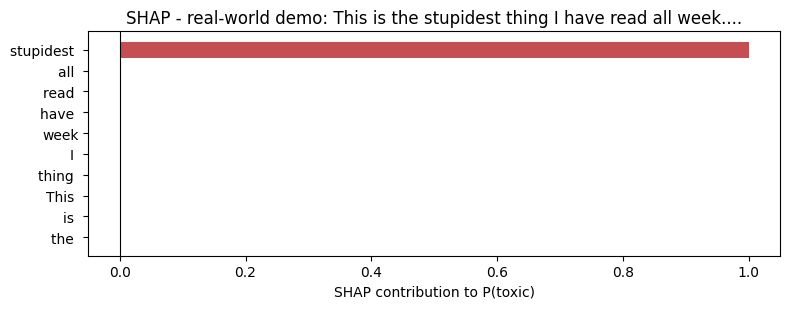

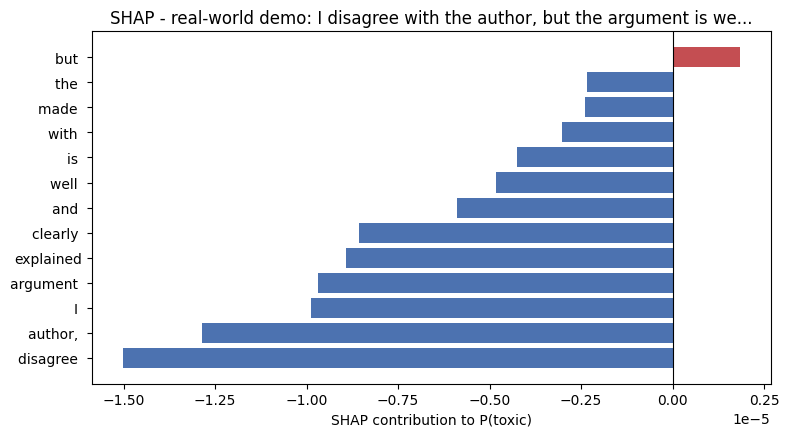

In [42]:
for tag, text in [("demo_toxic", DEMO_COMMENTS[2]),      # predicted toxic
                  ("demo_clean", DEMO_COMMENTS[1])]:     # predicted not toxic
    toks, vals = explain_text_shap(text)
    plot_token_contributions(toks, vals, f"SHAP - real-world demo: {text[:50]}...",
                             f"13_shap_{tag}.png")
